# Transport: Temporal-Coherence Figures (ERA5 corridor + HYSPLIT concentration profile)

Two candidate replacements/additions for the manuscript's Transport section
(`sec:transport_methods` / `sec:transport`), motivated by two problems raised
in review:

1. The ERA5-corridor validation currently compares against raw `AER_AI > 2.0`
   pixels on days without a hand-reviewed plume boundary (only 0118/0119 have
   one) — those pixels are fragmented/noisy on +2d/+3d and the corridor map is
   hard to read. Here we replace the pixel-overlap metric with a **temporal
   concentration-coherence** check: real TROPOMI CO, masked by the
   flux-independent 500-member ERA5 corridor (p > 1%), median + IQR over
   ~10 overpasses spanning -10d to +15d. This is the same idea prototyped in
   `notebooks/extra/co_background_temporal_mc.ipynb`, rerun here against the
   **current** canonical corridor (`outputs/pathway/corridor_prob.npy`, from
   `05_plume_pathway_ensemble.ipynb` post plume-boundary/alignment-gate fixes)
   rather than the stale prototype corridor (`outputs/mc_corridor_prob.npy`).

2. `tab:hysplit` only reports 4 daily snapshots. The underlying `cdump` is
   sampled 3-hourly over the full 120 h run, so we can plot the model's own
   rise/decay shape as a continuous curve instead of 4 disconnected rows, with
   the same 4 TROPOMI-matched points overlaid for reference.

Both figures reuse only existing outputs (`05_plume_pathway_ensemble.ipynb`,
`06_hysplit_forward_validation.ipynb`) — no HYSPLIT rerun, no new retrievals.

In [1]:
from __future__ import annotations
import os, warnings
from collections import defaultdict
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

_here = Path('.').resolve()
ROOT = next((p for p in [_here] + list(_here.parents)
             if (p / 'data').exists() and (p / 'src').exists()), None)
if ROOT is None:
    raise RuntimeError(f'Cannot locate project root from {_here}.')
os.chdir(ROOT)
print(f'Project root: {ROOT}')

from src.data_helpers import load_co_l2
from src import hysplit_helpers as H

DATA_DIR = ROOT / 'data'
OUT_DIR = ROOT / 'outputs' / 'transport_temporal'
OUT_DIR.mkdir(parents=True, exist_ok=True)

FIRE_LAT, FIRE_LON = -37.5484, -72.5545

plt.rcParams.update({
    'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10.5,
    'legend.fontsize': 8.5, 'xtick.labelsize': 8.5, 'ytick.labelsize': 8.5,
    'figure.dpi': 300, 'savefig.dpi': 300, 'axes.grid': True,
    'grid.alpha': 0.35, 'grid.linewidth': 0.4,
})

Project root: /Users/maperezc/Downloads/wildfires


## Part A — ERA5 corridor-masked TROPOMI CO: temporal coherence

**Mask:** the 500-member ERA5 release-uncertainty corridor from
`05_plume_pathway_ensemble.ipynb` (`outputs/pathway/corridor_prob.npy`),
thresholded at `p > 1%` — flux-independent, so this validation is not
entangled with the retrieved CO flux (unlike the HYSPLIT check in Part B).

**Claim under test:** real TROPOMI CO within this wind-derived footprint rises
on the fire day and decays back to the pre-fire baseline over the following
days — a signal that is robust to individual noisy pixels because it is a
median over hundreds of grid cells, not a pixel-by-pixel spatial-overlap
count.

In [2]:
# ── Part A config (explicit, no silent defaults) ─────────────────────────────
CORRIDOR_PROB_FILE = ROOT / 'outputs' / 'pathway' / 'corridor_prob.npy'
CORRIDOR_LAT_FILE  = ROOT / 'outputs' / 'pathway' / 'lat_edges.npy'
CORRIDOR_LON_FILE  = ROOT / 'outputs' / 'pathway' / 'lon_edges.npy'
for f in (CORRIDOR_PROB_FILE, CORRIDOR_LAT_FILE, CORRIDOR_LON_FILE):
    assert f.exists(), f'Missing corridor file: {f}. Run 05_plume_pathway_ensemble.ipynb first.'

MC_THRESHOLD = 0.01   # corridor visit-probability threshold (p > 1%), matches Methods sec:transport_methods
QA_MIN       = 0.5    # standard TROPOMI QA_MIN used throughout the paper
GRID_RES     = 0.1    # deg, rasterisation/binning resolution for the analysis grid

# ROI matches the HYSPLIT comparison domain in 06_hysplit_forward_validation.ipynb
# (same geographic extent as the corridor grid itself), so both figures cover
# an identical footprint.
ROI = dict(lat_min=-45.0, lat_max=-17.0, lon_min=-90.0, lon_max=-66.0)

# 10 TROPOMI overpasses spanning -10d..+15d from the fire (all L2 CO files per
# folder are used -- some days have >1 matched overpass -- rather than a single
# hardcoded filename, consistent with the pipeline's 'concatenate all matched
# L2 overpasses' convention).
DATES = [
    {'folder': '0108', 'date': 'Jan 08 2026', 'offset': -10, 'label': '-10d'},
    {'folder': '0113', 'date': 'Jan 13 2026', 'offset':  -5, 'label': '-5d'},
    {'folder': '0118', 'date': 'Jan 18 2026', 'offset':   0, 'label': '0d'},
    {'folder': '0119', 'date': 'Jan 19 2026', 'offset':  +1, 'label': '+1d'},
    {'folder': '0120', 'date': 'Jan 20 2026', 'offset':  +2, 'label': '+2d'},
    {'folder': '0121', 'date': 'Jan 21 2026', 'offset':  +3, 'label': '+3d'},
    {'folder': '0122', 'date': 'Jan 22 2026', 'offset':  +4, 'label': '+4d'},
    {'folder': '0123', 'date': 'Jan 23 2026', 'offset':  +5, 'label': '+5d'},
    {'folder': '0128', 'date': 'Jan 28 2026', 'offset': +10, 'label': '+10d'},
    {'folder': '0202', 'date': 'Feb 02 2026', 'offset': +15, 'label': '+15d'},
]
for entry in DATES:
    fs = sorted((DATA_DIR / entry['folder']).glob('S5P_OFFL_L2__CO_____*.nc'))
    assert fs, f"No CO L2 files found in data/{entry['folder']}"
    entry['files'] = fs

print(f'MC threshold : p > {MC_THRESHOLD:.0%}')
print(f'QA threshold : {QA_MIN}')
print(f'ROI          : {ROI}')
print(f'Dates        : {len(DATES)} overpasses, {DATES[0]["date"]} .. {DATES[-1]["date"]}')

MC threshold : p > 1%
QA threshold : 0.5
ROI          : {'lat_min': -45.0, 'lat_max': -17.0, 'lon_min': -90.0, 'lon_max': -66.0}
Dates        : 10 overpasses, Jan 08 2026 .. Feb 02 2026


In [3]:
# ── Build the binary plume mask on the analysis grid ─────────────────────────
corridor_prob = np.load(CORRIDOR_PROB_FILE)
corr_lat_edges = np.load(CORRIDOR_LAT_FILE)
corr_lon_edges = np.load(CORRIDOR_LON_FILE)
corr_lat_ctrs = 0.5 * (corr_lat_edges[:-1] + corr_lat_edges[1:])
corr_lon_ctrs = 0.5 * (corr_lon_edges[:-1] + corr_lon_edges[1:])
NLAT_C, NLON_C = len(corr_lat_ctrs), len(corr_lon_ctrs)
assert corridor_prob.shape == (NLAT_C, NLON_C), 'corridor_prob shape mismatch with its own edge files'

lat_edges = np.arange(ROI['lat_min'], ROI['lat_max'] + GRID_RES, GRID_RES)
lon_edges = np.arange(ROI['lon_min'], ROI['lon_max'] + GRID_RES, GRID_RES)
lat_ctrs = 0.5 * (lat_edges[:-1] + lat_edges[1:])
lon_ctrs = 0.5 * (lon_edges[:-1] + lon_edges[1:])
NLAT_G, NLON_G = len(lat_ctrs), len(lon_ctrs)

# Map each fine (0.1 deg) analysis cell to its parent corridor (0.25 deg) bin.
i_c = np.clip(np.searchsorted(corr_lat_edges, lat_ctrs) - 1, 0, NLAT_C - 1)
j_c = np.clip(np.searchsorted(corr_lon_edges, lon_ctrs) - 1, 0, NLON_C - 1)
plume_grid = corridor_prob[i_c[:, None], j_c[None, :]] > MC_THRESHOLD
assert plume_grid.sum() > 0, f'No plume cells at p > {MC_THRESHOLD:.0%} within ROI.'
print(f'Plume mask: {plume_grid.sum():,} cells @ {GRID_RES} deg '
      f'(corridor grid {corridor_prob.shape} @ 0.25 deg)')

Plume mask: 8,762 cells @ 0.1 deg (corridor grid (112, 100) @ 0.25 deg)


In [4]:
# ── Extract + bin CO within the plume mask, per overpass ─────────────────────
def extract_and_bin(files) -> np.ndarray:
    lat_chunks, lon_chunks, co_chunks = [], [], []
    for f in files:
        c = load_co_l2(f, lat_min=ROI['lat_min'], lat_max=ROI['lat_max'],
                        lon_min=ROI['lon_min'], lon_max=ROI['lon_max'],
                        qa_threshold=QA_MIN * 100)
        lat_chunks.append(c['lat']); lon_chunks.append(c['lon']); co_chunks.append(c['co'])
    lat = np.concatenate(lat_chunks); lon = np.concatenate(lon_chunks); co = np.concatenate(co_chunks)

    i_s = np.clip(((lat - ROI['lat_min']) / GRID_RES).astype(int), 0, NLAT_G - 1)
    j_s = np.clip(((lon - ROI['lon_min']) / GRID_RES).astype(int), 0, NLON_G - 1)
    in_plume = plume_grid[i_s, j_s]

    cell_vals: dict = defaultdict(list)
    for i, j, v, keep in zip(i_s, j_s, co, in_plume):
        if keep:
            cell_vals[(i, j)].append(v)
    grid = np.full((NLAT_G, NLON_G), np.nan)
    for (i, j), vals in cell_vals.items():
        grid[i, j] = np.median(vals)
    n_pixels = int(in_plume.sum())
    return grid, n_pixels

results = []
for entry in DATES:
    grid, n_px = extract_and_bin(entry['files'])
    vals = grid[plume_grid & np.isfinite(grid)]
    n_valid = len(vals)
    assert n_valid > 0, f"No valid in-plume cells for {entry['date']}"
    results.append({
        'offset': entry['offset'], 'date': entry['date'], 'label': entry['label'],
        'median': float(np.nanmedian(vals)), 'q25': float(np.nanpercentile(vals, 25)),
        'q75': float(np.nanpercentile(vals, 75)), 'n_pixels': n_px, 'n_cells': n_valid,
    })
    print(f"  {entry['date']:15s} ({entry['offset']:+4d} d)  n_px={n_px:5,}  "
          f"n_cells={n_valid:4d}  median={results[-1]['median']:.4f} mol/m2")

pre_fire = [r for r in results if r['offset'] in (-10, -5)]
assert len(pre_fire) == 2, f'Expected 2 pre-fire dates, found {len(pre_fire)}'
baseline_median = float(np.median([r['median'] for r in pre_fire]))
for r in results:
    r['delta'] = r['median'] - baseline_median
print(f'\nPre-fire baseline (median of -10d, -5d): {baseline_median:.4f} mol/m2')

  Jan 08 2026     ( -10 d)  n_px=  813  n_cells= 520  median=0.0166 mol/m2
  Jan 13 2026     (  -5 d)  n_px=4,022  n_cells=2308  median=0.0179 mol/m2


  Jan 18 2026     (  +0 d)  n_px=5,217  n_cells=3143  median=0.0216 mol/m2


  Jan 19 2026     (  +1 d)  n_px=4,754  n_cells=2776  median=0.0226 mol/m2
  Jan 20 2026     (  +2 d)  n_px=3,035  n_cells=1713  median=0.0217 mol/m2


  Jan 21 2026     (  +3 d)  n_px=4,501  n_cells=2615  median=0.0218 mol/m2


  Jan 22 2026     (  +4 d)  n_px=10,213  n_cells=5143  median=0.0198 mol/m2
  Jan 23 2026     (  +5 d)  n_px=6,384  n_cells=3705  median=0.0182 mol/m2


  Jan 28 2026     ( +10 d)  n_px=7,983  n_cells=4325  median=0.0173 mol/m2


  Feb 02 2026     ( +15 d)  n_px=11,250  n_cells=5769  median=0.0186 mol/m2

Pre-fire baseline (median of -10d, -5d): 0.0172 mol/m2


Saved: /Users/maperezc/Downloads/wildfires/outputs/transport_temporal/fig_era5_co_temporal_coherence.png


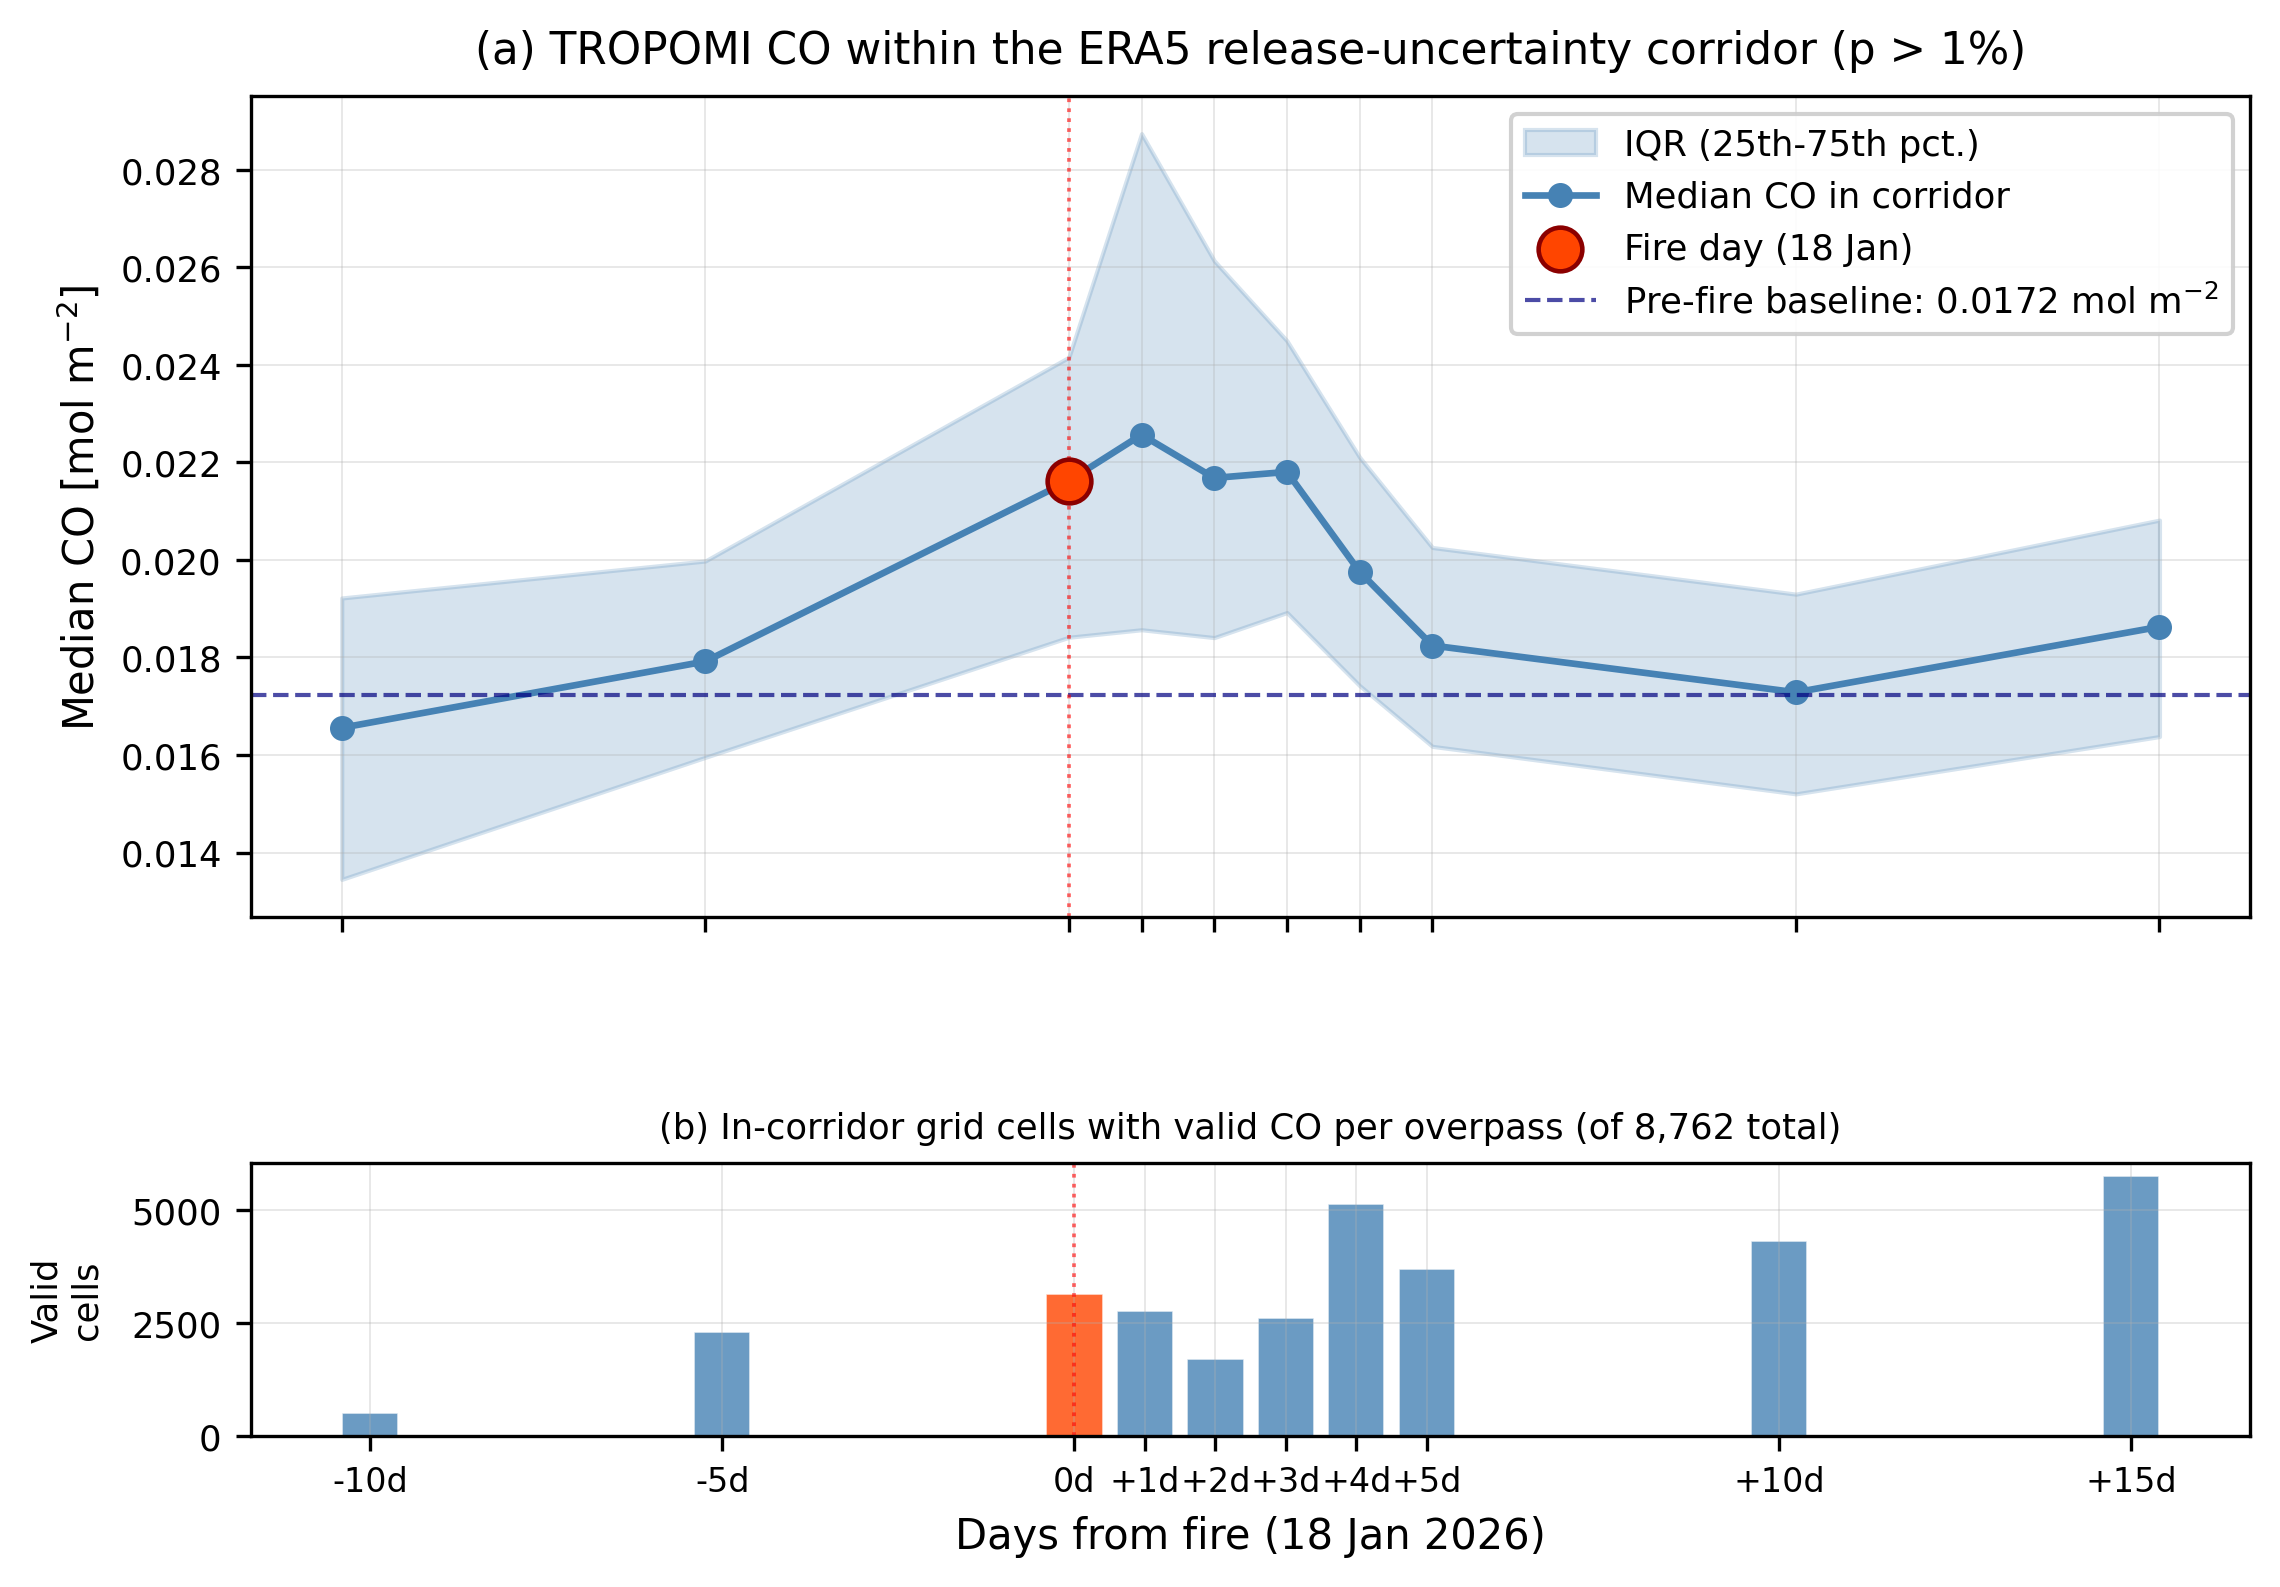

In [5]:
# ── Publication figure: median CO within the ERA5 corridor, over time ────────
offsets = [r['offset'] for r in results]
medians = [r['median'] for r in results]
q25s = [r['q25'] for r in results]
q75s = [r['q75'] for r in results]
labels = [r['label'] for r in results]
n_cells = [r['n_cells'] for r in results]
fire_idx = next(i for i, r in enumerate(results) if r['offset'] == 0)

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(8.6, 5.8),
                               gridspec_kw={'height_ratios': [3, 1], 'hspace': 0.45})

ax.fill_between(offsets, q25s, q75s, alpha=0.22, color='steelblue', label='IQR (25th-75th pct.)')
ax.plot(offsets, medians, 'o-', color='steelblue', lw=1.6, ms=5, label='Median CO in corridor')
ax.scatter([offsets[fire_idx]], [medians[fire_idx]], s=110, zorder=5,
           color='orangered', edgecolors='darkred', lw=1.1, label='Fire day (18 Jan)')
ax.axhline(baseline_median, color='navy', lw=1.0, ls='--', alpha=0.7,
           label=f'Pre-fire baseline: {baseline_median:.4f} mol m$^{{-2}}$')
ax.axvline(0, color='red', lw=0.9, ls=':', alpha=0.6)
ax.set_ylabel('Median CO [mol m$^{-2}$]')
ax.set_xticks(offsets)
ax.tick_params(axis='x', labelbottom=False)
ax.legend(loc='upper right', framealpha=0.9)
ax.set_title('(a) TROPOMI CO within the ERA5 release-uncertainty corridor (p > 1%)', pad=8)

ax2.bar(offsets, n_cells, width=0.8, color=['orangered' if o == 0 else 'steelblue' for o in offsets],
        alpha=0.8, edgecolor='white', lw=0.4)
ax2.set_ylabel('Valid\ncells', fontsize=8.5)
ax2.set_xticks(offsets); ax2.set_xticklabels(labels, fontsize=8, rotation=0)
ax2.set_xlabel('Days from fire (18 Jan 2026)')
ax2.axvline(0, color='red', lw=0.9, ls=':', alpha=0.6)
ax2.set_title(f'(b) In-corridor grid cells with valid CO per overpass '
              f'(of {plume_grid.sum():,} total)', fontsize=8.5, pad=6)

fig.align_ylabels([ax, ax2])
out_a = OUT_DIR / 'fig_era5_co_temporal_coherence.png'
fig.savefig(out_a, dpi=300, bbox_inches='tight')
print(f'Saved: {out_a}')
plt.show()

## Part B — HYSPLIT modeled CO column: continuous 3-hourly profile

Reads the same `cdump` used in `06_hysplit_forward_validation.ipynb`
(driven by the MC-median CO flux) and plots the modeled peak column at its
native 3-hourly sampling instead of only the 4 tabulated overpass snapshots.
Overlaid with the same 4 TROPOMI-matched points from `model_obs_comparison.csv`
for direct reference. No pre-fire baseline exists for the model curve (it is a
forward run seeded only by the fire), which is itself informative: unlike the
observed series in Part A, the modeled series starts at zero.

In [6]:
# ── Part B config (must match 06_hysplit_forward_validation.ipynb exactly) ───
CDUMP_PATH = ROOT / 'outputs' / 'hysplit_co' / 'run_0118' / 'cdump'
CMP_CSV = ROOT / 'outputs' / 'hysplit_co' / '0118' / 'model_obs_comparison.csv'
assert CDUMP_PATH.exists(), f'Missing cdump: {CDUMP_PATH}. Run 06_hysplit_forward_validation.ipynb first.'
assert CMP_CSV.exists(), f'Missing comparison table: {CMP_CSV}.'

CO_MOLAR_MASS_KG = 0.02801
LEVEL_TOP_M = 6000.0
RUN_START = datetime(2026, 1, 18, 10, 0)     # fire-active window start (UTC), matches nb06
EMISSION_HOURS = 12.0                         # 10-22 UTC fire-active window, matches nb06

_res = pd.read_csv(ROOT / 'outputs' / 'retrievals' / '0118' / 'co_distribution.csv',
                    index_col=0)['value']
CSF_CO_KG_S = float(_res['median'])
print(f'Retrieved CSF CO flux (source term, for the figure title): {CSF_CO_KG_S:.1f} kg/s')

Retrieved CSF CO flux (source term, for the figure title): 1273.3 kg/s


In [7]:
# ── Read the full 3-hourly cdump; modeled column & IN-REGION median series ───
# Match 06_hysplit_forward_validation.ipynb: compare within the modeled plume
# footprint (col > T_COL, > NEAR_SRC_KM from source), NOT the domain maximum
# (which is dominated by the near-source emission-window spike). The continuous
# curve is the modeled median column inside that footprint at each 3-hourly step.
from src import transport_compare as tc

# Same settings and implementation as 06_hysplit_forward_validation.ipynb
# (config/hysplit_comparison.yaml + src/transport_compare.py): analysis grid,
# threshold T, near-source exclusion and the containing-cell index regrid.
CMP = tc.load_comparison_config(ROOT / 'config' / 'hysplit_comparison.yaml')
assert (CMP.fire_lat, CMP.fire_lon, CMP.level_top_m, CMP.co_molar_mass_kg_per_mol) == \
       (FIRE_LAT, FIRE_LON, LEVEL_TOP_M, CO_MOLAR_MASS_KG), 'notebook constants differ from the comparison config'
T_COL       = CMP.threshold_mol_m2
NEAR_SRC_KM = CMP.near_source_km
GRID = tc.analysis_grid(CMP)
g_dist = tc.source_distance_km(CMP, GRID)

ds = H.read_cdump(CDUMP_PATH)
col_mol = tc.model_column_mol_m2(ds, CMP)   # mol/m2
mod_times = pd.to_datetime(ds.time.values)
elapsed_h = np.array([(t - RUN_START).total_seconds() / 3600.0 for t in mod_times])
regrid = tc.IndexRegrid(ds.latitude.values, ds.longitude.values, GRID)
med_series = tc.footprint_median_series(col_mol, regrid, g_dist,
                                        threshold_mol_m2=T_COL, near_source_km=NEAR_SRC_KM)
print(f'Modeled in-region median series: {len(mod_times)} steps, '
      f'{elapsed_h.min():.0f}-{elapsed_h.max():.0f} h, peak median={np.nanmax(med_series):.4f} mol/m2')

cmp_df = pd.read_csv(CMP_CSV)
cmp_df['model_time'] = pd.to_datetime(cmp_df['model_time'])
cmp_df['elapsed_h'] = [(t - RUN_START).total_seconds() / 3600.0 for t in cmp_df['model_time']]

# Sanity: the full-footprint median series must equal nb06's tabulated
# full-footprint median (mod_footprint_median_molm2, rounded to 5 decimals) at the
# four overpasses -- same grid, threshold and regrid, so the match is exact.
for _, row in cmp_df.iterrows():
    k = int(np.argmin(np.abs(elapsed_h - row['elapsed_h'])))
    assert round(med_series[k], 5) == row['mod_footprint_median_molm2'], (
        f"+{int(row['offset_d'])}d footprint median {med_series[k]:.5f} != "
        f"table {row['mod_footprint_median_molm2']:.5f}")
print('Sanity check passed: footprint-median series equals model_obs_comparison.csv at the 4 overpasses.')

Please install s3fs if retrieving from the Amazon S3 Servers.  Otherwise continue with local data
Please install h5netcdf to open files from the Amazon S3 servers.
Modeled in-region median series: 40 steps, 0-117 h, peak median=0.0154 mol/m2
Sanity check passed: footprint-median series equals model_obs_comparison.csv at the 4 overpasses.


Saved: /Users/maperezc/Downloads/wildfires/outputs/transport_temporal/fig_hysplit_co_temporal_profile.png


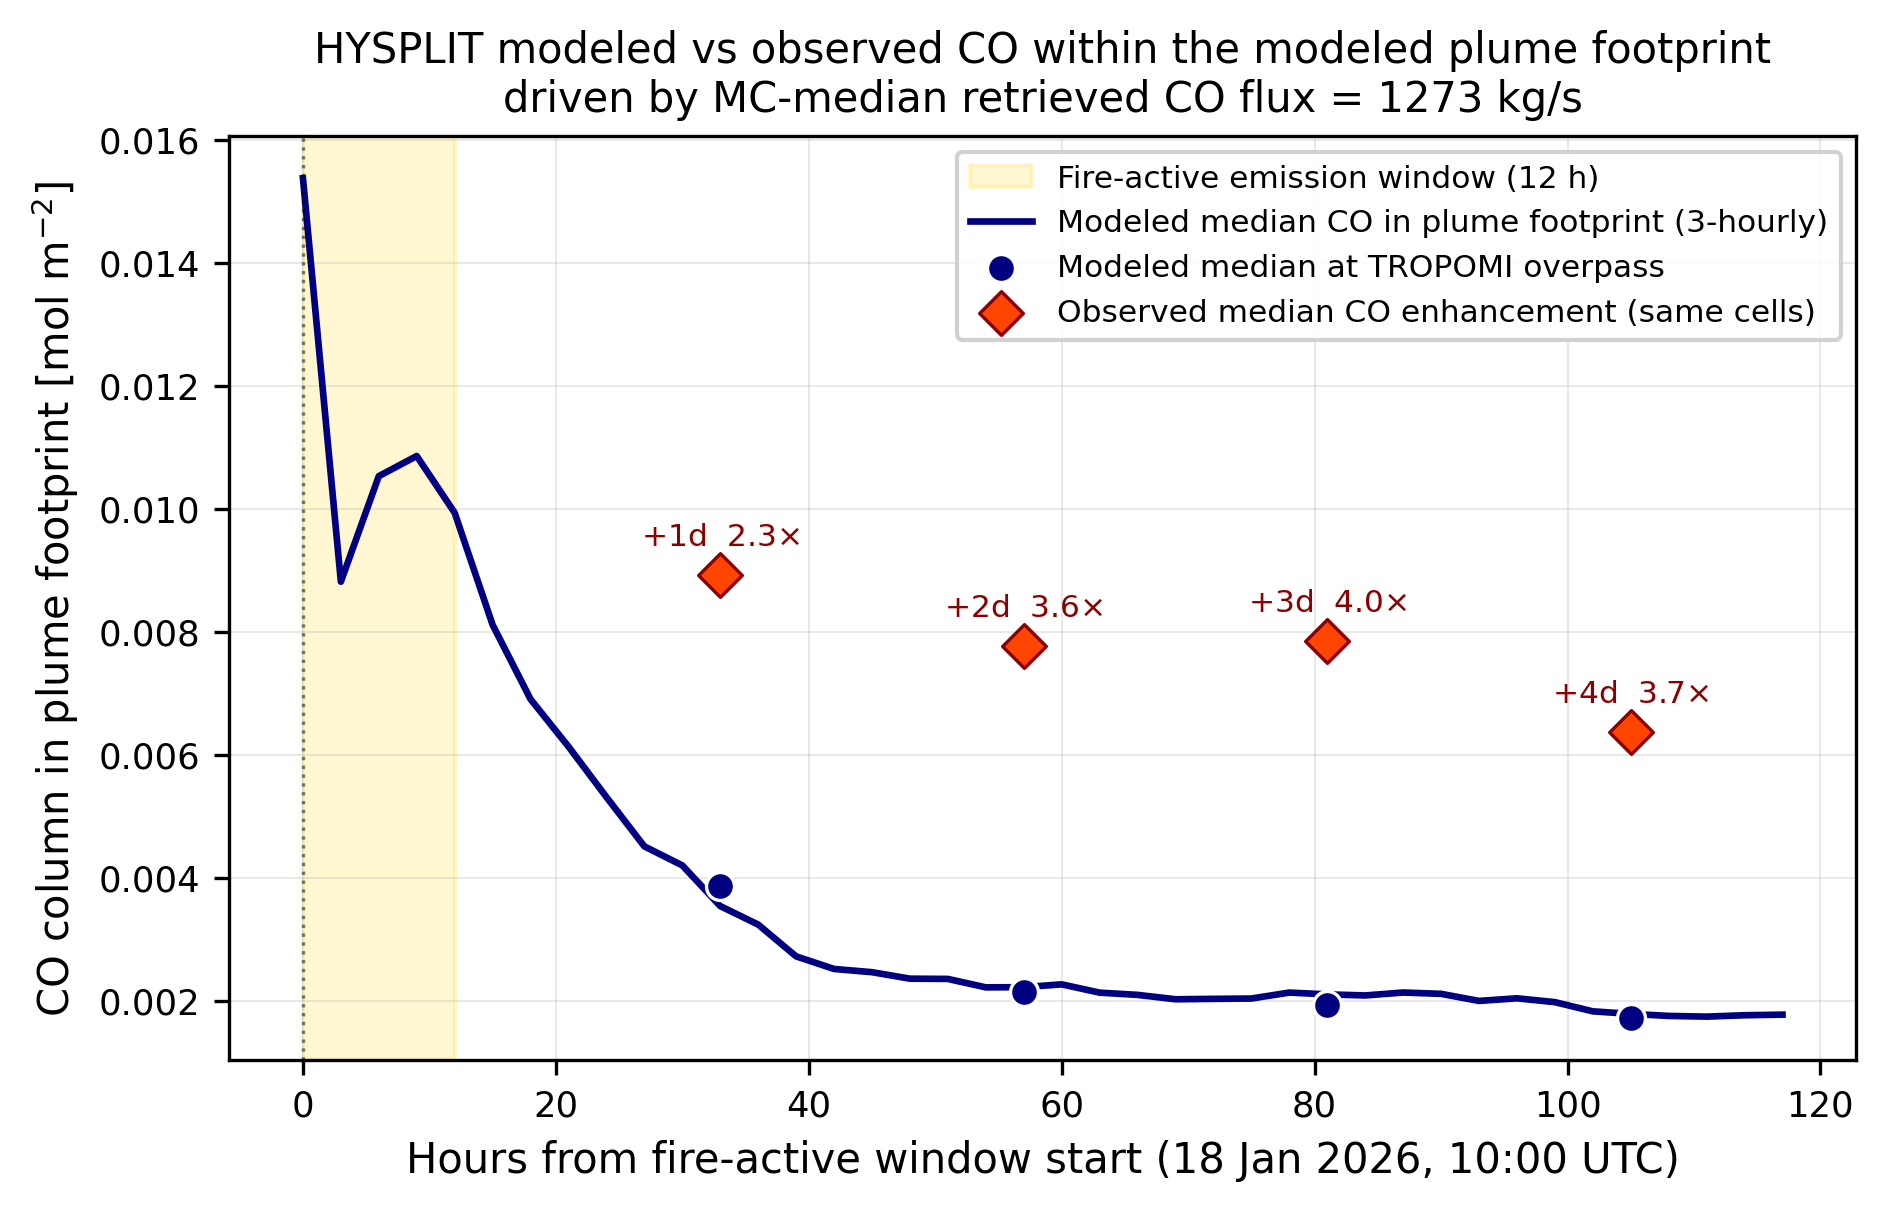

In [8]:
# ── Publication figure: modeled vs observed CO median WITHIN the footprint ────
fig, ax = plt.subplots(figsize=(7.0, 4.0))

ax.axvspan(0, EMISSION_HOURS, color='gold', alpha=0.18, label='Fire-active emission window (12 h)')
ax.plot(elapsed_h, med_series, '-', color='navy', lw=1.6,
        label='Modeled median CO in plume footprint (3-hourly)')
ax.scatter(cmp_df['elapsed_h'], cmp_df['mod_median_molm2'], marker='o', s=45,
           facecolor='navy', edgecolor='white', lw=0.8, zorder=5,
           label='Modeled median at TROPOMI overpass')
ax.scatter(cmp_df['elapsed_h'], cmp_df['obs_median_molm2'], marker='D', s=55,
           facecolor='orangered', edgecolor='darkred', lw=0.8, zorder=5,
           label='Observed median CO enhancement (same cells)')

for _, row in cmp_df.iterrows():
    ax.annotate(f"+{int(row['offset_d'])}d  {row['obs_over_mod']:.1f}$\\times$",
                xy=(row['elapsed_h'], row['obs_median_molm2']),
                xytext=(0, 7), textcoords='offset points', ha='center', fontsize=7.5, color='darkred')

ax.axvline(0, color='k', lw=0.8, ls=':', alpha=0.5)
ax.set_xlabel('Hours from fire-active window start (18 Jan 2026, 10:00 UTC)')
ax.set_ylabel('CO column in plume footprint [mol m$^{-2}$]')
ax.set_title('HYSPLIT modeled vs observed CO within the modeled plume footprint\n'
             f'driven by MC-median retrieved CO flux = {CSF_CO_KG_S:.0f} kg/s', fontsize=10)
ax.legend(loc='upper right', framealpha=0.9, fontsize=7.5)

out_b = OUT_DIR / 'fig_hysplit_co_temporal_profile.png'
fig.savefig(out_b, dpi=300, bbox_inches='tight')
print(f'Saved: {out_b}')
plt.show()

## Part C — Manuscript temporal figure (HYSPLIT only, single panel)

`fig_transport_combined.png`: the modeled median CO column within the plume
footprint over the full 3-hourly run, with the four TROPOMI-matched overpasses
(modeled median vs observed median enhancement over the same cells, annotated
with the observed/modeled ratio). The ERA5 corridor panel was removed from the
paper; this is now a single HYSPLIT panel.

Saved: /Users/maperezc/Downloads/wildfires/outputs/transport_temporal/fig_transport_combined.png
Copied to manuscript figures dir: /Users/maperezc/Downloads/wildfires/paper_staging/figures/fig_transport_combined.png

Converted to molec cm^-2 (factor 6.0221e+19):
  peak modeled median      : 9.262e+17
  modeled median at +48 h  : 1.423e+17
  +1d  model 2.331e+17   obs 5.378e+17   obs/mod 2.3
  +2d  model 1.289e+17   obs 4.685e+17   obs/mod 3.6
  +3d  model 1.168e+17   obs 4.733e+17   obs/mod 4.0
  +4d  model 1.036e+17   obs 3.842e+17   obs/mod 3.7


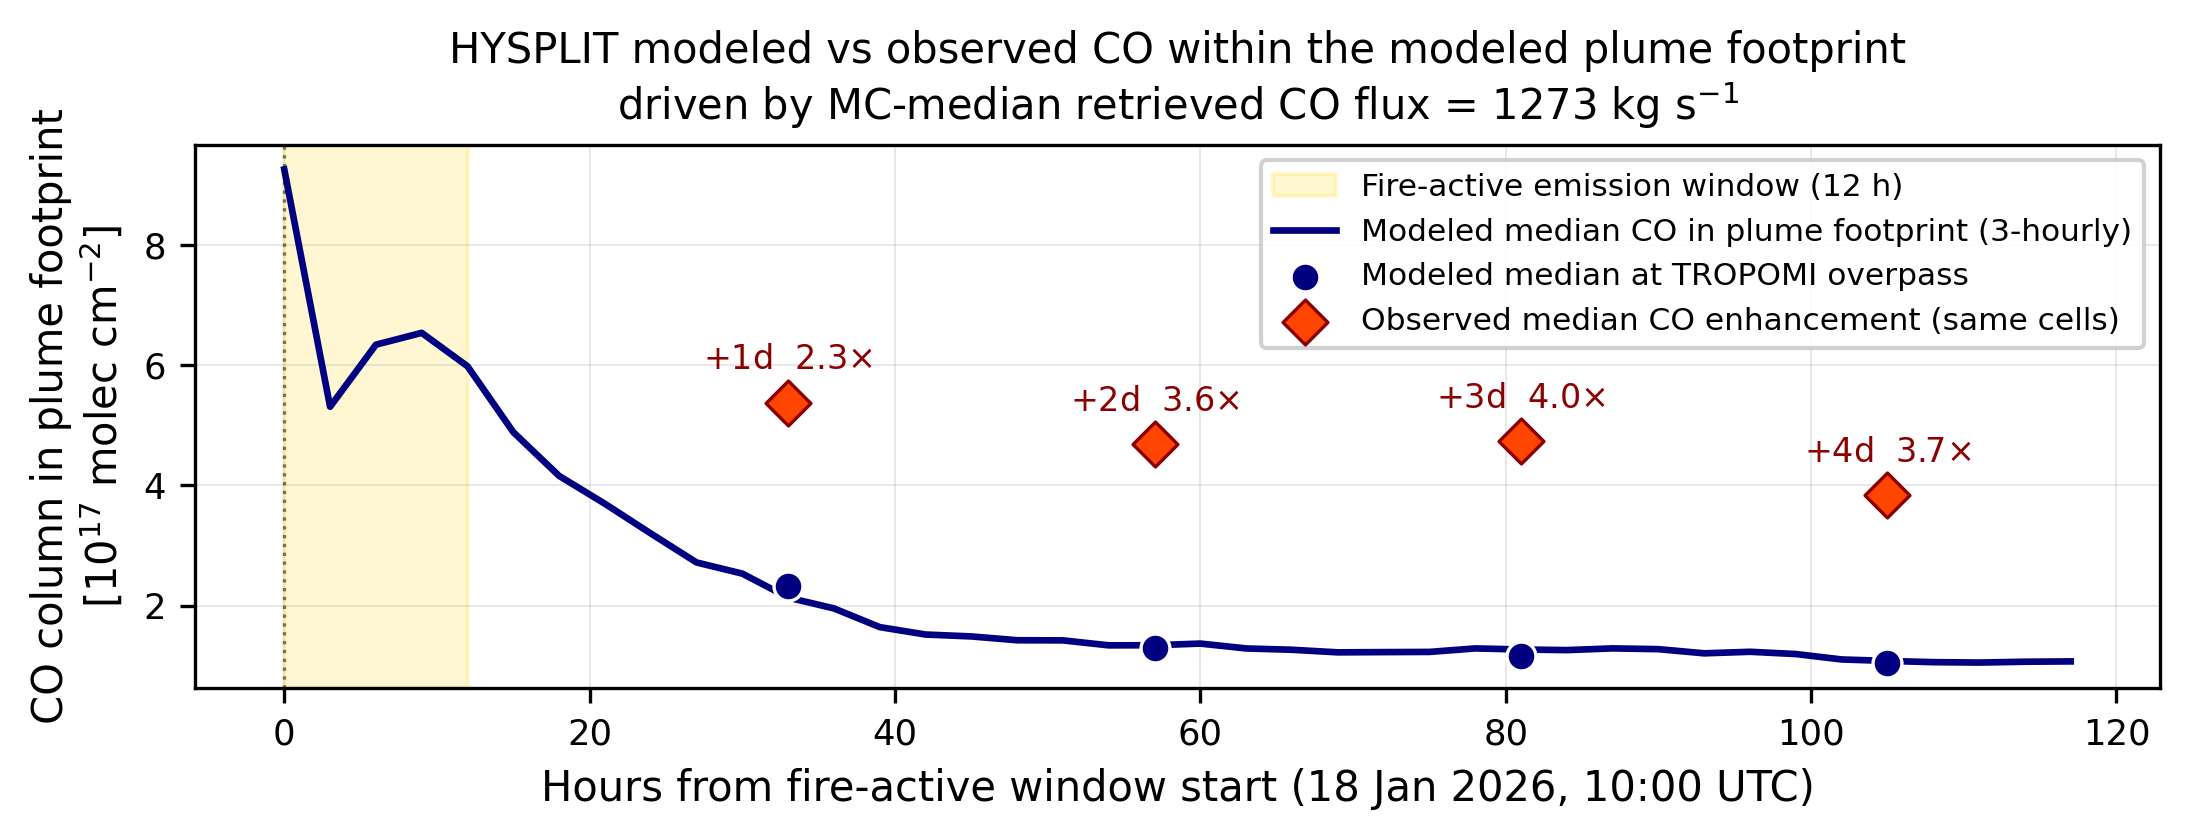

In [9]:
# ── Manuscript temporal figure: HYSPLIT modeled vs observed CO in footprint ──
# Single panel (HYSPLIT only; the ERA5 corridor panel was removed from the paper).
import shutil

# Manuscript Section 3.3 reports CO columns in molec cm^-2, while the pipeline
# carries them in mol m^-2 (cell above, `col_mol`). Convert at plot time only:
# stored outputs (model_obs_comparison.csv, med_series) stay in mol m^-2.
AVOGADRO_PER_MOL: float = 6.02214076e23                  # CODATA, exact by SI definition
MOL_M2_TO_MOLEC_CM2: float = AVOGADRO_PER_MOL / 1.0e4    # = 6.02214076e19
# Plot in 1e17 molec cm^-2 so matplotlib emits no offset text (the "1e17" corner
# label collides with the y-axis label at this panel height).
Y_UNIT: float = 1.0e17
MOL_M2_TO_AXIS: float = MOL_M2_TO_MOLEC_CM2 / Y_UNIT

med_series_axis = med_series * MOL_M2_TO_AXIS

fig, ax = plt.subplots(figsize=(7.4, 2.9))

ax.axvspan(0, EMISSION_HOURS, color='gold', alpha=0.18, label='Fire-active emission window (12 h)')
ax.plot(elapsed_h, med_series_axis, '-', color='navy', lw=1.6,
        label='Modeled median CO in plume footprint (3-hourly)')
ax.scatter(cmp_df['elapsed_h'], cmp_df['mod_median_molm2'] * MOL_M2_TO_AXIS, marker='o', s=48,
           facecolor='navy', edgecolor='white', lw=0.8, zorder=5,
           label='Modeled median at TROPOMI overpass')
ax.scatter(cmp_df['elapsed_h'], cmp_df['obs_median_molm2'] * MOL_M2_TO_AXIS, marker='D', s=58,
           facecolor='orangered', edgecolor='darkred', lw=0.8, zorder=5,
           label='Observed median CO enhancement (same cells)')
for _, row in cmp_df.iterrows():
    ax.annotate(f"+{int(row['offset_d'])}d  {row['obs_over_mod']:.1f}$\\times$",
                xy=(row['elapsed_h'], row['obs_median_molm2'] * MOL_M2_TO_AXIS),
                xytext=(0, 8), textcoords='offset points', ha='center', fontsize=8, color='darkred')
ax.axvline(0, color='k', lw=0.8, ls=':', alpha=0.5)
ax.set_xlabel('Hours from fire-active window start (18 Jan 2026, 10:00 UTC)')
ax.set_ylabel('CO column in plume footprint\n[10$^{17}$ molec cm$^{-2}$]')
ax.set_title('HYSPLIT modeled vs observed CO within the modeled plume footprint\n'
             f'driven by MC-median retrieved CO flux = {CSF_CO_KG_S:.0f} kg s$^{{-1}}$', fontsize=10)
ax.legend(loc='upper right', framealpha=0.9, fontsize=7.5)

fig.tight_layout()
out_c = OUT_DIR / 'fig_transport_combined.png'
fig.savefig(out_c, dpi=300, bbox_inches='tight')
print(f'Saved: {out_c}')
paper_fig_path = ROOT / 'paper_staging' / 'figures' / 'fig_transport_combined.png'
paper_fig_path.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(out_c, paper_fig_path)
print(f'Copied to manuscript figures dir: {paper_fig_path}')

# Manuscript-facing values in the converted unit (Section 3.3 text).
print(f'\nConverted to molec cm^-2 (factor {MOL_M2_TO_MOLEC_CM2:.4e}):')
print(f'  peak modeled median      : {np.nanmax(med_series) * MOL_M2_TO_MOLEC_CM2:.3e}')
_k48 = int(np.argmin(np.abs(elapsed_h - 48.0)))
print(f'  modeled median at +48 h  : {med_series[_k48] * MOL_M2_TO_MOLEC_CM2:.3e}')
for _, row in cmp_df.iterrows():
    print(f"  +{int(row['offset_d'])}d  model {row['mod_median_molm2'] * MOL_M2_TO_MOLEC_CM2:.3e}"
          f"   obs {row['obs_median_molm2'] * MOL_M2_TO_MOLEC_CM2:.3e}"
          f"   obs/mod {row['obs_over_mod']:.1f}")
plt.show()


## Part D — Spatial transport figure (HYSPLIT only, 1×4 time series)

`fig_transport_spatial.png`: a single row of the four downwind overpasses
($+$1..$+$4 d). Each panel shows the observed TROPOMI CO enhancement (shading;
column minus the same-day 10th-percentile off-plume background) overlaid with the
HYSPLIT modeled plume drawn as a single smooth footprint-boundary contour at
$T = 5\times10^{-4}$ mol m$^{-2}$ (white). The modeled field is Gaussian-smoothed
and upsampled before contouring — display-only; the comparison numbers in nb06
use the raw field. CO only — no AER\_AI, no ERA5 corridor. Time-evolving because
HYSPLIT is a dispersion run; the modeled and observed plumes advance
north-northwestward together over the four days.

In [10]:
# ── Part D config: map domain (identical to the ERA5 corridor grid & nb06) ───
# Same analysis grid, background percentile and overpasses as nb06
# (config/hysplit_comparison.yaml; CMP / GRID loaded in Part B above).
MAP_LAT_MIN, MAP_LAT_MAX = CMP.lat_min, CMP.lat_max
MAP_LON_MIN, MAP_LON_MAX = CMP.lon_min, CMP.lon_max
BG_PCT  = CMP.bg_percentile
map_lat_edges, map_lon_edges = GRID.lat_edges, GRID.lon_edges
map_lat_ctrs, map_lon_ctrs = GRID.lat_ctrs, GRID.lon_ctrs
MAP_OVERPASSES = [{'folder': o['folder'], 'offset': o['offset_d'], 'dt': o['time_utc']} for o in CMP.overpasses]

def bin_co_map(folder) -> np.ndarray:
    return tc.bin_observed_co(sorted((DATA_DIR / folder).glob('S5P_OFFL_L2__CO_____*.nc')), CMP, GRID)

obs_enh = {}
for ov in MAP_OVERPASSES:
    g = bin_co_map(ov['folder'])
    bg = np.nanpercentile(g, BG_PCT)
    obs_enh[ov['offset']] = g - bg
    print(f"+{ov['offset']}d: bg(p{BG_PCT:.0f})={bg*1e3:.1f} mmol/m2, "
          f"peak enh={np.nanmax(g-bg)*1e3:.1f} mmol/m2")

# ERA5-panel composite: cell-wise max enhancement over the four downwind days
with warnings.catch_warnings():
    warnings.simplefilter('ignore', category=RuntimeWarning)  # all-NaN cells -> NaN
    composite_enh = np.nanmax(np.stack([obs_enh[o] for o in (1, 2, 3, 4)], axis=0), axis=0)
print(f'composite peak enhancement: {np.nanmax(composite_enh)*1e3:.1f} mmol/m2')

+1d: bg(p10)=15.3 mmol/m2, peak enh=71.1 mmol/m2


+2d: bg(p10)=14.6 mmol/m2, peak enh=54.6 mmol/m2
+3d: bg(p10)=13.8 mmol/m2, peak enh=96.5 mmol/m2


+4d: bg(p10)=13.8 mmol/m2, peak enh=40.5 mmol/m2
composite peak enhancement: 96.5 mmol/m2


Colour scale: 0 to 1.02 x 1e18 molec cm^-2
Saved: /Users/maperezc/Downloads/wildfires/outputs/transport_temporal/fig_transport_spatial.png
Copied to manuscript figures dir: /Users/maperezc/Downloads/wildfires/paper_staging/figures/fig_transport_spatial.png


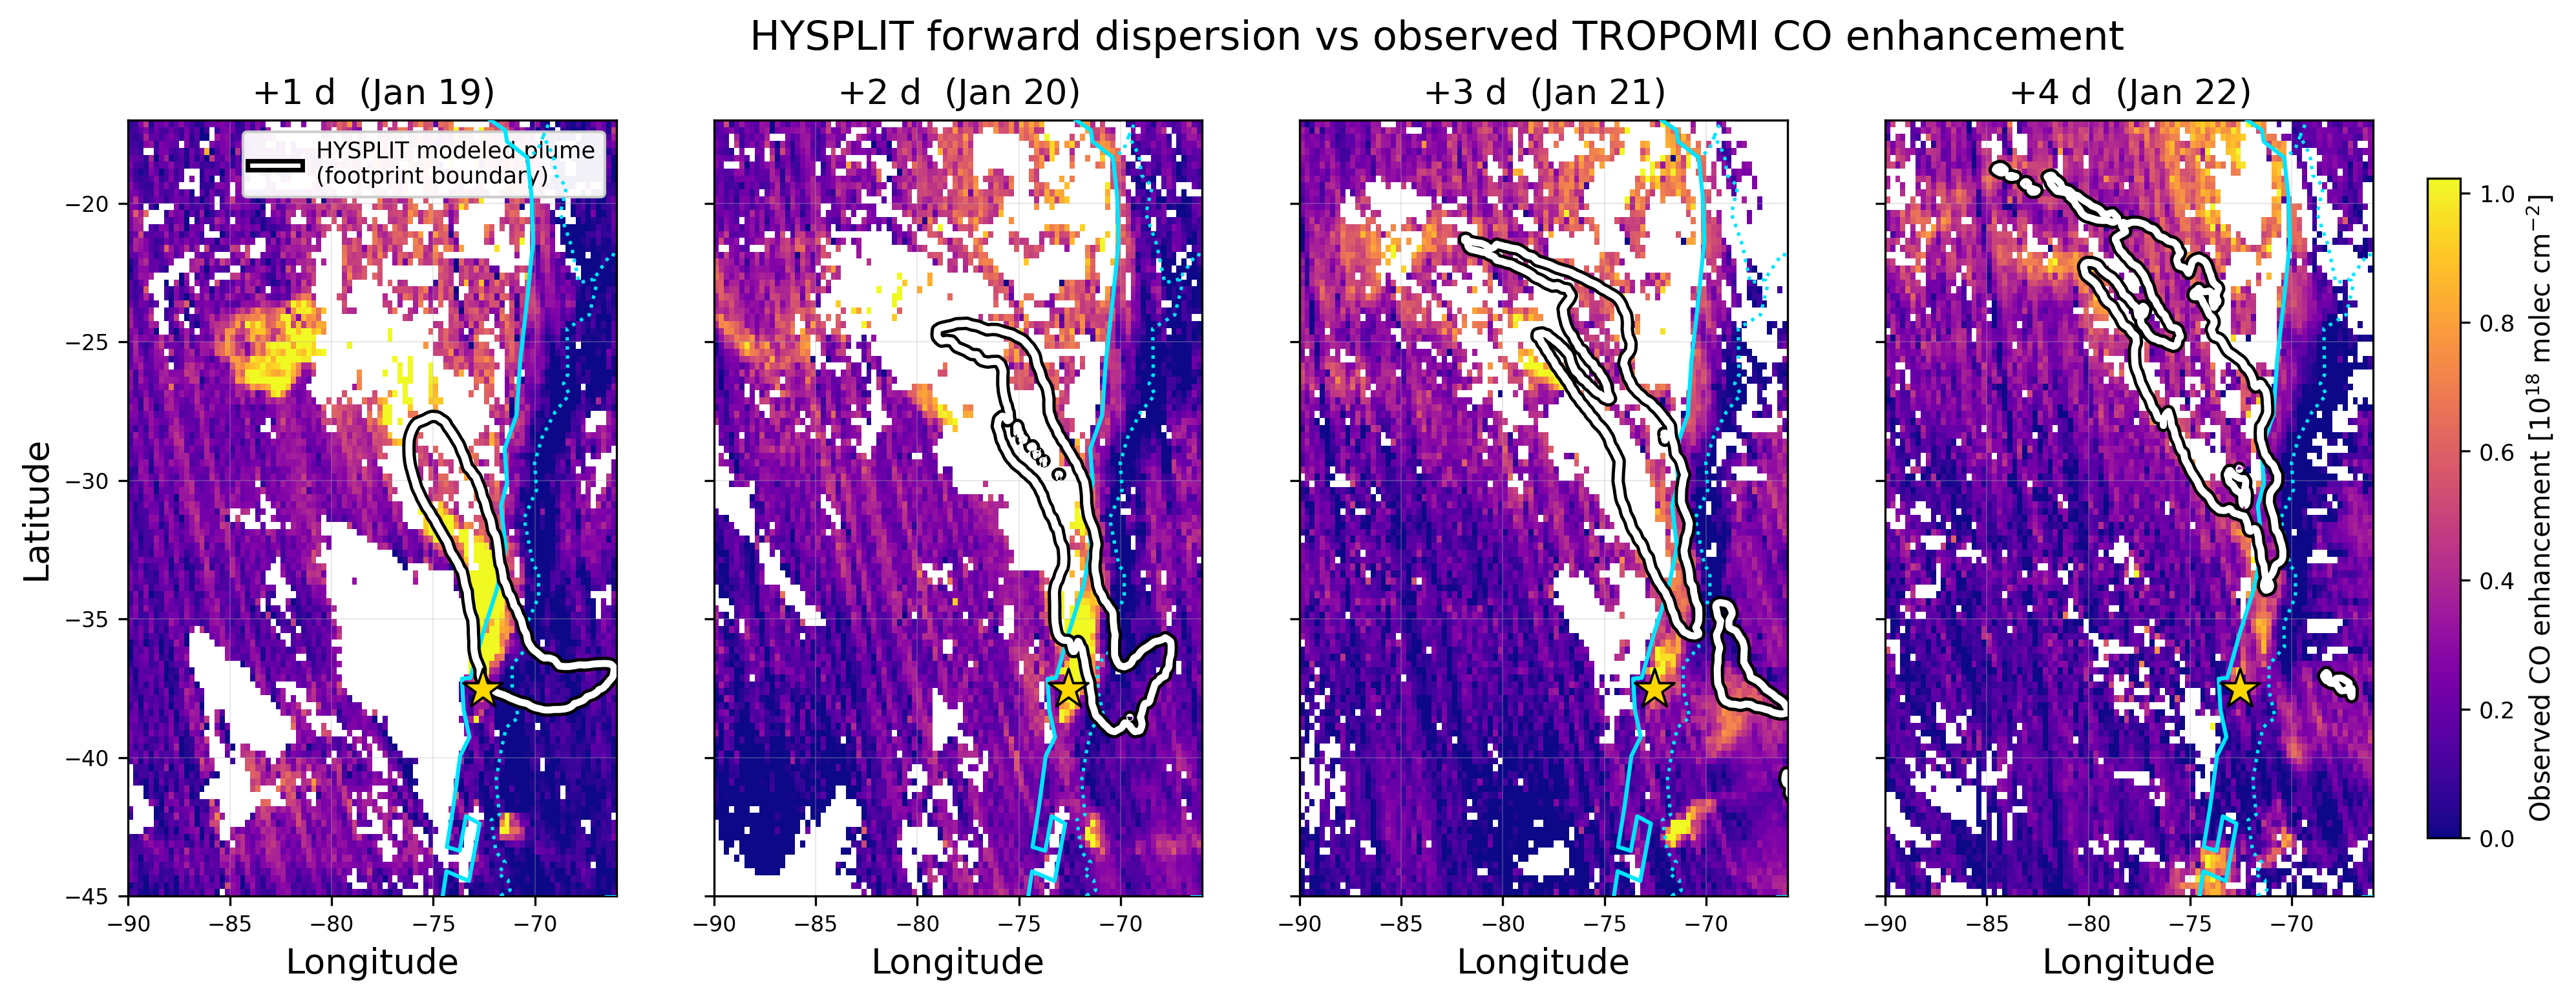

In [11]:
# ── Part D figure: HYSPLIT forward dispersion, 4 overpass days (1x4 row) ──────
# HYSPLIT only (ERA5 corridor panel + observed composite removed). Each panel is
# one downwind overpass: observed TROPOMI CO enhancement (shading) with the
# HYSPLIT modeled column drawn as a single smooth footprint-boundary contour.
# The modeled field is Gaussian-smoothed and upsampled BEFORE contouring
# (display-only; the comparison numbers in nb06 use the raw field) so the plume
# reads as one clean outline rather than a jagged pixel-edge contour.
import shutil
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe
from scipy.ndimage import gaussian_filter, zoom
import cartopy.io.shapereader as shpreader
from shapely.geometry import box as shapely_box

mod_lon2d = np.asarray(ds.longitude.values)   # cdump lat/lon are 2D (y, x)
mod_lat2d = np.asarray(ds.latitude.values)
MOD_COL_THRESH = 1.0e-3   # mol/m2 modeled-column footprint boundary (matches nb06 T)
SMOOTH_SIGMA = 0.0        # Gaussian smoothing (grid cells) applied before contouring
UPSAMPLE = 4              # contour on an upsampled grid for smooth curves

CO_CMAP = 'plasma'
CONTOUR_C = 'white'
COAST_C = '#00e5ff'   # cyan
HALO = [pe.withStroke(linewidth=5.0, foreground='black')]

# Natural Earth 110m coastline + national borders, clipped to the map domain
_land = list(shpreader.Reader(shpreader.natural_earth(
    resolution='110m', category='physical', name='land')).geometries())
_bord = list(shpreader.Reader(shpreader.natural_earth(
    resolution='110m', category='cultural', name='admin_0_boundary_lines_land')).geometries())
_dbox = shapely_box(MAP_LON_MIN, MAP_LAT_MIN, MAP_LON_MAX, MAP_LAT_MAX)

def _draw_coast(ax, lw=1.5, z=6):
    for g in _land:
        if not g.intersects(_dbox):
            continue
        for p in (g.geoms if g.geom_type == 'MultiPolygon' else [g]):
            ax.plot(*p.exterior.xy, color=COAST_C, lw=lw, zorder=z)
    for g in _bord:
        if not g.intersects(_dbox):
            continue
        for ln in (g.geoms if g.geom_type == 'MultiLineString' else [g]):
            ax.plot(*ln.xy, color=COAST_C, lw=lw * 0.85, ls=':', zorder=z)

# smoothed/upsampled model grid (regular -> zoom keeps it regular)
lon_hi = zoom(mod_lon2d, UPSAMPLE, order=1)
lat_hi = zoom(mod_lat2d, UPSAMPLE, order=1)

# Colourbar in 1e18 molec cm^-2, matching Section 3.3 and the manuscript temporal
# figure. MOL_M2_TO_MOLEC_CM2 is defined with that figure earlier in this notebook.
CB_UNIT: float = 1.0e18
MOL_M2_TO_CB: float = MOL_M2_TO_MOLEC_CM2 / CB_UNIT   # mol m^-2 -> 1e18 molec cm^-2

# common observed-CO-enhancement colour scale (1e18 molec cm^-2) across the four panels
allvals = np.concatenate([obs_enh[o][np.isfinite(obs_enh[o])] for o in (1, 2, 3, 4)]) * MOL_M2_TO_CB
vmax = float(np.nanpercentile(allvals, 99))

fig, axes = plt.subplots(1, 4, figsize=(18.0, 5.2), sharey=True)
for ax, ov in zip(axes, MAP_OVERPASSES):
    pm = ax.pcolormesh(map_lon_edges, map_lat_edges, obs_enh[ov['offset']] * MOL_M2_TO_CB, cmap=CO_CMAP,
                       vmin=0, vmax=vmax, shading='flat', zorder=1)
    _draw_coast(ax, lw=1.5)
    k = int(np.argmin(np.abs(mod_times - pd.Timestamp(ov['dt']))))
    mfield = np.nan_to_num(np.asarray(col_mol.isel(time=k).values, float), nan=0.0)
    msm = zoom(gaussian_filter(mfield, sigma=SMOOTH_SIGMA), UPSAMPLE, order=1)  # smooth then upsample
    if (msm > MOD_COL_THRESH).any():
        csb = ax.contour(lon_hi, lat_hi, msm, levels=[MOD_COL_THRESH],
                         colors=CONTOUR_C, linewidths=2.6, zorder=7)
        csb.set_path_effects(HALO)
    ax.scatter(FIRE_LON, FIRE_LAT, marker='*', s=240, c='gold', edgecolors='k',
               linewidths=0.9, zorder=10)
    ax.set_xlim(MAP_LON_MIN, MAP_LON_MAX); ax.set_ylim(MAP_LAT_MIN, MAP_LAT_MAX)
    ax.set_title(f"$+${ov['offset']} d  ({ov['dt']:%b %d})", fontsize=13)
    ax.set_xlabel('Longitude', fontsize=13)
    ax.tick_params(labelsize=8)
axes[0].set_ylabel('Latitude', fontsize=13)
axes[0].legend([Line2D([0], [0], color=CONTOUR_C, lw=1.6, path_effects=HALO)],
               ['HYSPLIT modeled plume\n(footprint boundary)'], loc='upper right',
               fontsize=8.5, framealpha=0.95)
fig.suptitle('HYSPLIT forward dispersion vs observed TROPOMI CO enhancement',
             fontsize=15)
cb = fig.colorbar(pm, ax=axes, shrink=0.85, pad=0.02, location='right')
cb.set_label('Observed CO enhancement [10$^{18}$ molec cm$^{-2}$]')

print(f'Colour scale: 0 to {vmax:.2f} x 1e18 molec cm^-2')

out_d = OUT_DIR / 'fig_transport_spatial.png'
fig.savefig(out_d, dpi=300, bbox_inches='tight')
print(f'Saved: {out_d}')
shutil.copy2(out_d, ROOT / 'paper_staging' / 'figures' / 'fig_transport_spatial.png')
print(f"Copied to manuscript figures dir: {ROOT / 'paper_staging' / 'figures' / 'fig_transport_spatial.png'}")
plt.show()

## Summary

- `outputs/transport_temporal/fig_era5_co_temporal_coherence.png` — real
  TROPOMI CO within the flux-independent ERA5 corridor, median + IQR over
  -10d..+15d (temporal coherence).
- `outputs/transport_temporal/fig_hysplit_co_temporal_profile.png` — the
  modeled CO column's continuous 3-hourly rise/decay, with the 4 overpass
  points overlaid.
- `outputs/transport_temporal/fig_transport_combined.png` — temporal two-panel
  (ERA5 coherence + HYSPLIT profile).
- `outputs/transport_temporal/fig_transport_spatial.png` — **spatial** figure:
  (a) observed CO composite + ERA5 96-h corridor contour (CO only, no AER_AI);
  (b) HYSPLIT 2x2 dispersion days. This is the one that gives the ERA5 corridor
  a map, addressing reviewer concern #1.

All computed from existing pipeline outputs only (no reruns). Next step,
pending review: wire the chosen figure(s) into `agusample.tex`.